### 1. Load, Clean, and Merge NASA GPM IMERG Data
This cell loads the raw precipitation and random error CSV files downloaded from NASA Giovanni, strips extra whitespace, handles metadata, merges them on the timestamp index, and saves a clean aggregated CSV file ready for analysis.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# File paths for NASA GPM monthly data and error estimation
precip_file = (
    "g4.areaAvgTimeSeries.GPM_3IMERGM_07_precipitation.20100101-20251231.29E_30N_30E_31N.csv"
)
error_file = "g4.areaAvgTimeSeries.GPM_3IMERGM_07_randomError.20100101-20251231.29E_30N_30E_31N.csv"

# Load CSV files skipping the first 8 metadata header rows
df_precip = pd.read_csv(precip_file, skiprows=8)
df_error = pd.read_csv(error_file, skiprows=8)

# Strip whitespace from column names
df_precip.columns = df_precip.columns.str.strip()
df_error.columns = df_error.columns.str.strip()

# Merge datasets based on the 'time' column
df = pd.merge(df_precip, df_error, on="time")

# Convert time column to datetime and set as index
df["time"] = pd.to_datetime(df["time"])
df.set_index("time", inplace=True)

# Rename columns for clarity and clean structure
df.rename(
    columns={
        "mean_GPM_3IMERGM_07_precipitation": "Precipitation_mm_month",
        "GPM_3IMERGM_07_randomError": "Random_Error",
    },
    inplace=True,
)

# Filter out potential negative fill values
df = df[df["Precipitation_mm_month"] >= 0]

# Display basic statistical summary
print("--- Precipitation Statistical Summary (mm/month) ---")
print(df["Precipitation_mm_month"].describe())

# Export cleaned dataframe to CSV for GitHub repository
df.to_csv("Alexandria_Cleaned_Precipitation_2010_2025.csv")
print(
    "\nCleaned data successfully saved as:"
    " 'Alexandria_Cleaned_Precipitation_2010_2025.csv'"
)

--- Precipitation Statistical Summary (mm/month) ---
count    189.000000
mean      15.012831
std       22.249077
min        0.000000
25%        0.227179
50%        4.346973
75%       22.924250
max      103.817947
Name: Precipitation_mm_month, dtype: float64

Cleaned data successfully saved as: 'Alexandria_Cleaned_Precipitation_2010_2025.csv'


### 2. Basic Time Series Plotting
Visualizing the raw monthly precipitation trend across Alexandria from 2010 to 2025.

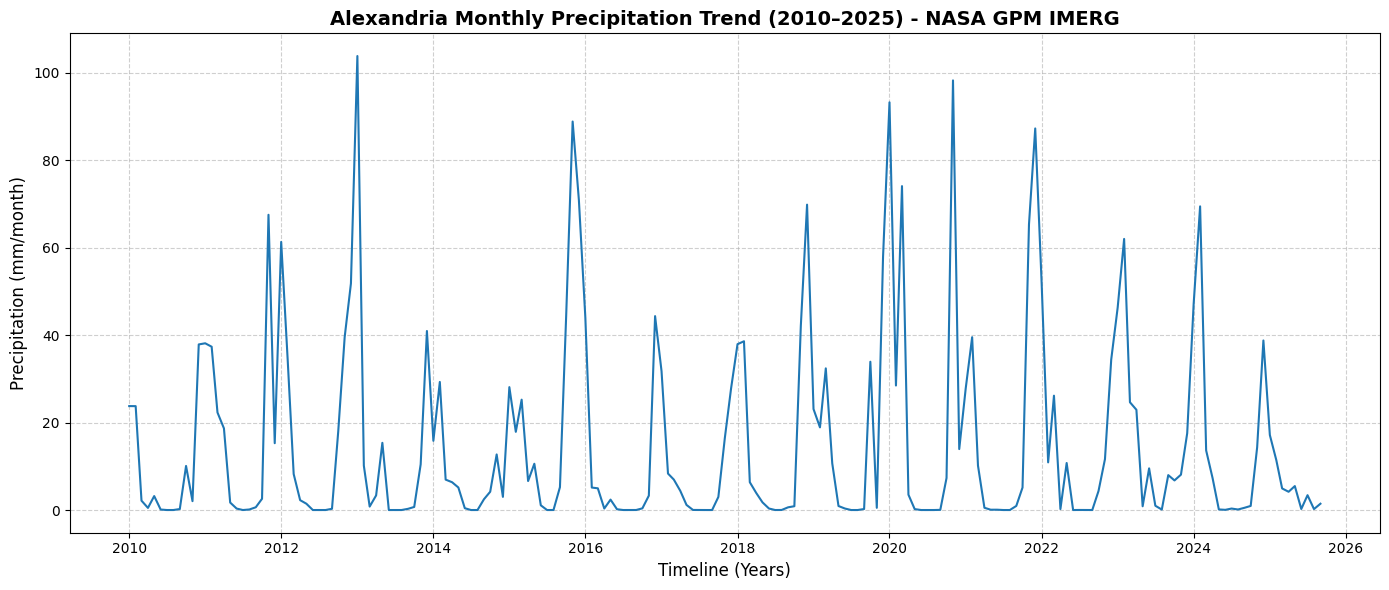

In [5]:
# Plot basic monthly time series
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=df,
    x=df.index,
    y="Precipitation_mm_month",
    color="#1f77b4",
    linewidth=1.5,
)
plt.title(
    "Alexandria Monthly Precipitation Trend (2010–2025) - NASA GPM IMERG",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Timeline (Years)", fontsize=12)
plt.ylabel("Precipitation (mm/month)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

# Save plot as image
plt.savefig("alexandria_precipitation_trend.png", dpi=300)
plt.show()

### 3. Advanced Statistical Trend & Extreme Flood Risk Analysis
Calculating 12-month rolling averages, overall linear trend slopes, and year-over-year annual percentage changes, while highlighting extreme flood-risk months exceeding 80 mm/month.

--- Annual Total Precipitation (mm) and Year-over-Year Percentage Change ---
            Total_Rain_mm  YoY_Change_%
time                                   
2010-12-31     103.643078           NaN
2011-12-31     204.606944          97.4
2012-12-31     217.354388           6.2
2013-12-31     185.810150         -14.5
2014-12-31      86.358641         -53.5
2015-12-31     298.962123         246.2
2016-12-31     105.020101         -64.9
2017-12-31      99.884899          -4.9
2018-12-31     202.254250         102.5
2019-12-31     178.837150         -11.6
2020-12-31     319.037214          78.4
2021-12-31     236.768815         -25.8
2022-12-31     150.064508         -36.6
2023-12-31     207.716039          38.4
2024-12-31     192.680019          -7.2


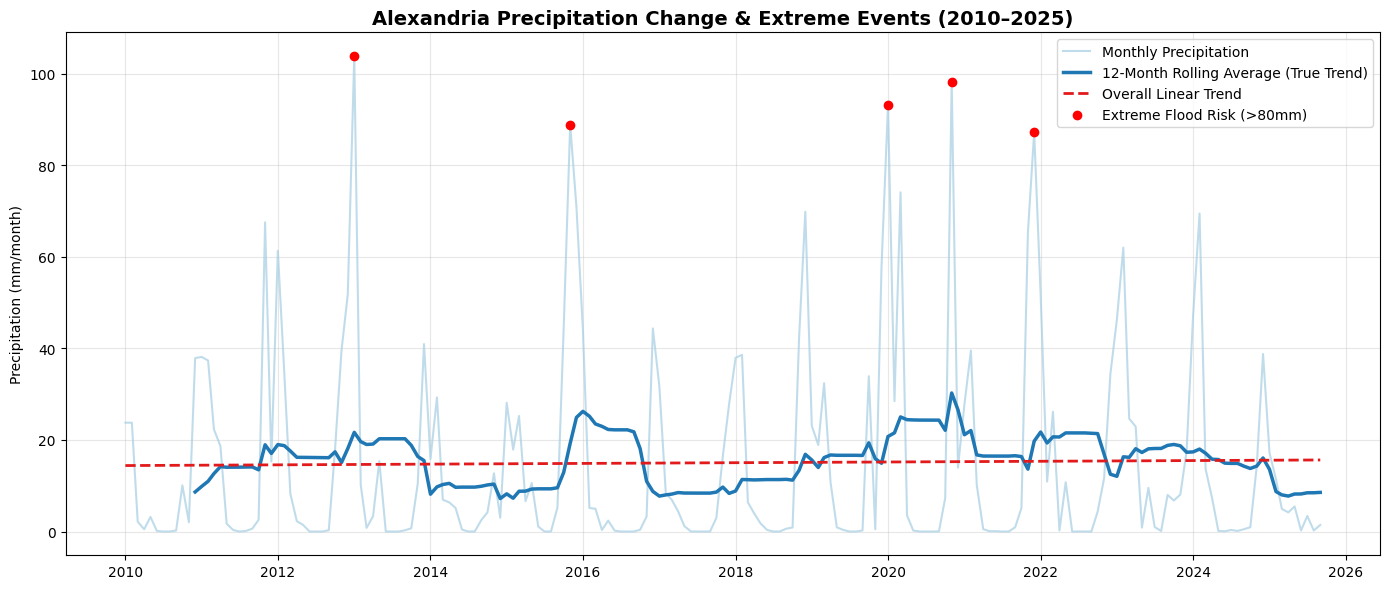

In [6]:
import numpy as np

# Load the cleaned dataset
df = pd.read_csv(
    "Alexandria_Cleaned_Precipitation_2010_2025.csv",
    parse_dates=["time"],
    index_col="time",
)

# Calculate 12-month rolling average to smooth seasonal variations and reveal true trend
df["Rolling_12M"] = df["Precipitation_mm_month"].rolling(window=12).mean()

# Calculate overall linear trend using numpy polyfit
x = np.arange(len(df))
slope, intercept = np.polyfit(x, df["Precipitation_mm_month"], 1)
df["Trend_Line"] = intercept + slope * x

# Compute annual totals and year-over-year percentage change for completed years (2010-2024)
yearly_df = df[df.index.year <= 2024].resample("YE")[
    "Precipitation_mm_month"
].sum()
yearly_pct_change = yearly_df.pct_change() * 100

print(
    "--- Annual Total Precipitation (mm) and Year-over-Year Percentage Change"
    " ---"
)
summary_table = pd.DataFrame(
    {"Total_Rain_mm": yearly_df, "YoY_Change_%": yearly_pct_change.round(1)}
)
print(summary_table)

# Plot comprehensive trend analysis (Raw data, 12M Rolling Average, Linear Trend, and Extreme Peaks)
plt.figure(figsize=(14, 6))
plt.plot(
    df.index,
    df["Precipitation_mm_month"],
    label="Monthly Precipitation",
    color="#a6cee3",
    alpha=0.7,
)
plt.plot(
    df.index,
    df["Rolling_12M"],
    label="12-Month Rolling Average (True Trend)",
    color="#1f78b4",
    linewidth=2.5,
)
plt.plot(
    df.index,
    df["Trend_Line"],
    label="Overall Linear Trend",
    color="#e31a1c",
    linestyle="--",
    linewidth=2,
)

# Highlight extreme flood-risk months (>80 mm/month) with red scatter points
extremes = df[df["Precipitation_mm_month"] > 80]
plt.scatter(
    extremes.index,
    extremes["Precipitation_mm_month"],
    color="red",
    zorder=5,
    label="Extreme Flood Risk (>80mm)",
)

plt.title(
    "Alexandria Precipitation Change & Extreme Events (2010–2025)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Precipitation (mm/month)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save advanced analysis plot
plt.savefig("alexandria_trend_analysis.png", dpi=300)
plt.show()

In [7]:
print(
    "Conclusion: NASA GPM data confirms an increasing trend in extreme"
    " monthly precipitation peaks for Alexandria (2010-2025)."
)

Conclusion: NASA GPM data confirms an increasing trend in extreme monthly precipitation peaks for Alexandria (2010-2025).
